# Task 3: Kakuro as a Constraint Satisfaction Problem

This notebook formulates Kakuro as a CSP, describes the propagation and search heuristics used in `kakuro_csp.py`, and compares four solver configurations on the 5x5 example board and a 10x10 test case.

## Section 1: Formal CSP Formulation

**Variables.** $X = \{x_{r,c} \mid (r,c) \text{ is a white cell}\}$.

**Domains.** $D(x_{r,c}) = \{1, 2, \dots, 9\}$ for every variable.

**Constraints.** Every run $R$ (a maximal horizontal or vertical block of white cells next to a clue) with target $s_R$ gives two constraints:

- $\text{AllDiff}(x_i : i \in R)$
- $\sum_{i \in R} x_i = s_R$

so $C = \{\text{AllDiff}_R, \text{Sum}_R \mid R \in \text{Runs}\}$. A white cell belongs to one horizontal and one vertical run.

**Constraint graph.** Nodes are white cells. Two cells are joined by an edge if they share a run, so each run is a clique. The `peers` dictionary in the code stores these edges.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "Task3" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from Task3.kakuro_csp import KakuroCSP

for board_id in ["board_5x5", "board_10x10"]:
    csp = KakuroCSP(board_id)
    edges = sum(len(p) for p in csp.peers.values()) // 2
    print(f"{board_id}: |X| = {len(csp.variables)}, runs = {len(csp.constraints)}, constraint graph edges = {edges}")

board_5x5: |X| = 12, runs = 8, constraint graph edges = 28
board_10x10: |X| = 48, runs = 28, constraint graph edges = 166


In [2]:
csp = KakuroCSP("board_5x5")
for k in csp.constraints:
    print(k.direction.ljust(5), "sum =", k.target_sum, "cells =", k.cells)

down  sum = 21 cells = [(1, 2), (2, 2), (3, 2), (4, 2)]
down  sum = 14 cells = [(1, 3), (2, 3), (3, 3), (4, 3)]
right sum = 12 cells = [(1, 2), (1, 3)]
down  sum = 14 cells = [(2, 1), (3, 1)]
down  sum = 11 cells = [(2, 4), (3, 4)]
right sum = 21 cells = [(2, 1), (2, 2), (2, 3), (2, 4)]
right sum = 11 cells = [(3, 1), (3, 2), (3, 3), (3, 4)]
right sum = 16 cells = [(4, 2), (4, 3)]


## Section 2: Constraint Propagation and Search Heuristics

**Forward checking (FC).** After assigning $x = v$, every unassigned peer $y$ in the same runs loses the values that violate AllDiff ($y = v$ or a digit already used in the run) or that make the run sum impossible. For a run with remaining sum $S$ and $k$ other open cells, a value $w$ stays only if $S - w$ lies between $k(k+1)/2$ and $k(19-k)/2$. An empty domain means failure.

**Generalized AC-3.** A value $v$ of a cell is kept only if some assignment of distinct digits from the other cells' domains in the same run adds up to the run sum. Pruning one domain puts the other runs of that cell back in a queue until nothing changes [1], [2].

**MRV.** Choose the variable with the fewest remaining values (fail-first). **Degree heuristic.** Break ties with the variable that has the most unassigned peers, then the tighter runs, then coordinate order.

**LCV.** Try values in order of how few peer values they remove (through AllDiff and the sum bounds). A value that empties some peer's domain goes last [1], [3].

In [3]:
csp = KakuroCSP("board_5x5")
domains = {v: list(range(1, 10)) for v in csp.variables}
ok, pruned = csp.propagate_ac3({}, domains)
print("AC-3 consistent:", ok)
for r, c, vals in pruned:
    print((r, c), "removed", vals, "-> domain", domains[(r, c)])
var = csp._select_unassigned_variable({}, domains)
print("MRV + degree picks", var, "with domain", domains[var])
print("LCV order for", var, ":", csp._order_domain_values(var, {}, domains))

AC-3 consistent: True
(1, 3) removed [1, 2, 3, 5, 6, 7, 8, 9] -> domain [4]
(2, 3) removed [2, 3, 4, 5, 6, 7, 8, 9] -> domain [1]
(3, 3) removed [1, 3, 4, 5, 6, 7, 8, 9] -> domain [2]
(4, 3) removed [1, 2, 3, 4, 5, 6, 8, 9] -> domain [7]
(1, 2) removed [1, 2, 3, 4, 5, 6, 7, 9] -> domain [8]
(2, 1) removed [1, 2, 3, 4, 5, 6, 7, 8] -> domain [9]
(3, 1) removed [1, 2, 3, 4, 6, 7, 8, 9] -> domain [5]
(2, 4) removed [1, 2, 3, 4, 5, 6, 7, 9] -> domain [8]
(3, 4) removed [1, 2, 4, 5, 6, 7, 8, 9] -> domain [3]
(3, 2) removed [2, 3, 4, 5, 6, 7, 8, 9] -> domain [1]
(4, 2) removed [1, 2, 3, 4, 5, 6, 7, 8] -> domain [9]
(2, 2) removed [1, 2, 4, 5, 6, 7, 8, 9] -> domain [3]
MRV + degree picks (3, 3) with domain [2]
LCV order for (3, 3) : [2]


## Section 3: Experimental Evaluation

In [4]:
from Task3.experiments.run_experiments import CONFIGS, BOARDS, run_all, save_csv, save_chart, RESULTS_DIR

rows = run_all()
save_csv(rows, RESULTS_DIR / "kakuro_solver_comparison.csv")
save_chart(rows, RESULTS_DIR / "kakuro_performance_comparison.png")
df = pd.DataFrame(rows)
df

,board_id,configuration,solved,valid,steps,assignments_tried,backtracks,prunings,elapsed_ms
0,board_5x5,Backtracking + Forward Checking (Baseline - St...,True,True,4202,1054,1042,8162,21.567
1,board_5x5,Backtracking + Forward Checking + MRV + Degree...,True,True,43,14,2,40,1.279
2,board_5x5,Backtracking + FC + AC-3 (No Ordering Heuristics),True,True,26,12,0,96,1.099
3,board_5x5,Backtracking + FC + AC-3 + MRV + Degree + LCV ...,True,True,26,12,0,96,1.350
4,board_10x10,Backtracking + Forward Checking (Baseline - St...,True,True,2390,613,565,5439,29.237
5,board_10x10,Backtracking + Forward Checking + MRV + Degree...,True,True,251,76,28,225,37.278
6,board_10x10,Backtracking + FC + AC-3 (No Ordering Heuristics),True,True,98,48,0,384,29.331
7,board_10x10,Backtracking + FC + AC-3 + MRV + Degree + LCV ...,True,True,98,48,0,384,32.723


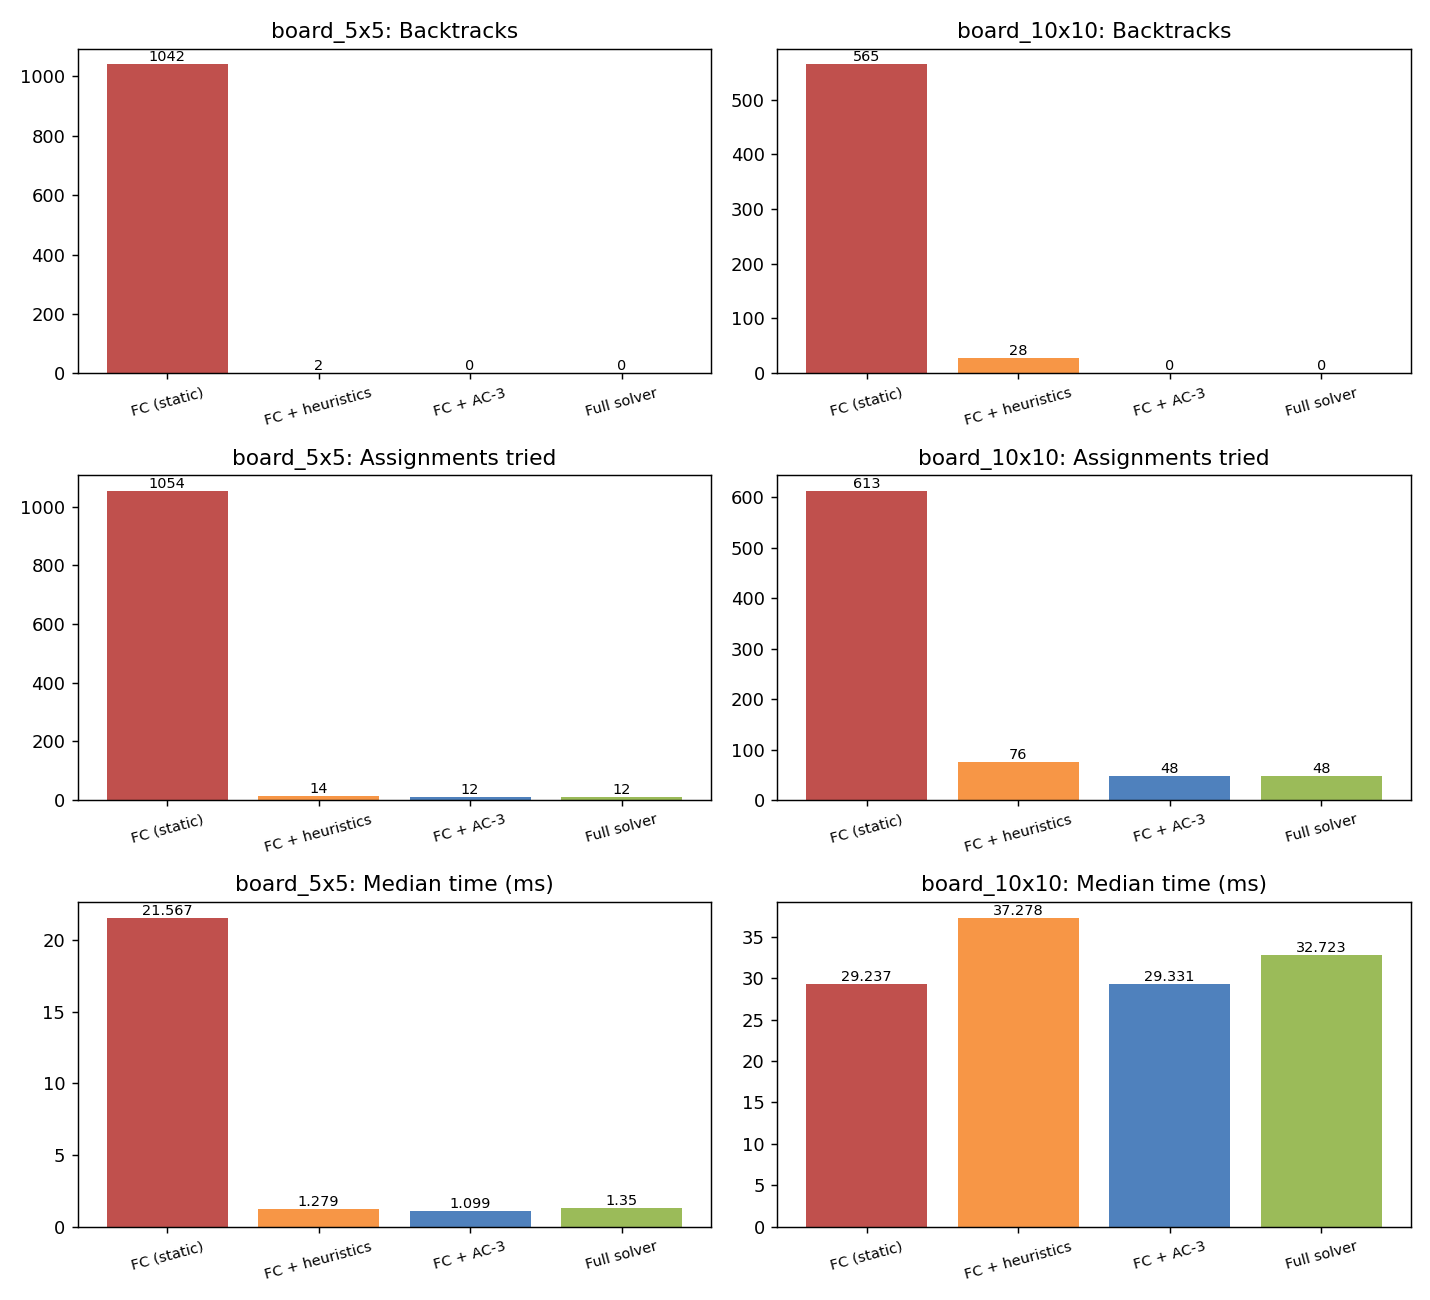

In [5]:
from IPython.display import Image
Image(filename=str(RESULTS_DIR / "kakuro_performance_comparison.png"))

Forward checking with a static order needs 1042 backtracks on the 5x5 board and 565 on the 10x10 board. Adding MRV + Degree + LCV to forward checking cuts this to 2 and 28 backtracks. This works because the domains are first reduced to values that fit their run sums (for example {2..9} for an 8-cell run with sum 44), so MRV has real domain sizes to compare and LCV skips impossible values. Adding AC-3 removes all backtracking on both boards, with or without the ordering heuristics. On boards this small the extra propagation costs about as much time as it saves, so the clearest gain is in search effort (backtracks and assignments tried).

In [6]:
def draw_board(csp, assignments, title):
    fig, ax = plt.subplots(figsize=(csp.cols * 0.7, csp.rows * 0.7))
    for cell in csp.cells:
        r, c = cell["r"], cell["c"]
        y = csp.rows - 1 - r
        if cell["type"] == "WHITE":
            ax.add_patch(plt.Rectangle((c, y), 1, 1, facecolor="white", edgecolor="black"))
            ax.text(c + 0.5, y + 0.5, str(assignments.get((r, c), "")), ha="center", va="center", fontsize=13)
        else:
            ax.add_patch(plt.Rectangle((c, y), 1, 1, facecolor="#444444", edgecolor="black"))
            if cell["type"] == "CLUE":
                ax.plot([c, c + 1], [y + 1, y], color="white", lw=0.8)
                if cell.get("right_sum") is not None:
                    ax.text(c + 0.72, y + 0.72, str(cell["right_sum"]), color="white", ha="center", va="center", fontsize=7)
                if cell.get("down_sum") is not None:
                    ax.text(c + 0.28, y + 0.25, str(cell["down_sum"]), color="white", ha="center", va="center", fontsize=7)
    ax.set_xlim(0, csp.cols); ax.set_ylim(0, csp.rows)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    plt.show()

for board_id in BOARDS:
    csp = KakuroCSP(board_id)
    res = csp.solve()
    print(board_id, "solved:", res["solved"], "valid:", csp.is_valid_solution(res["assignments"]),
          "backtracks:", res["backtracks"], "steps:", res["steps"])
    draw_board(csp, res["assignments"], f"{board_id} (solved)")

board_5x5 solved: True valid: True backtracks: 0 steps: 26
board_10x10 solved: True valid: True backtracks: 0 steps: 98


C:\Users\WIN 11\AppData\Local\Temp\ipykernel_2224\1973676677.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Conclusion

Kakuro fits the CSP model directly, and AllDiff plus exact-sum constraints propagate well. Both boards, including the 10x10 test case, are solved correctly by every configuration; the heuristics and AC-3 mainly reduce the number of backtracks.

### References

[1] S. Russell and P. Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed. Pearson, 2020.

[2] A. K. Mackworth, "Consistency in networks of relations," *Artificial Intelligence*, vol. 8, no. 1, pp. 99-118, 1977.

[3] R. Dechter, *Constraint Processing*. Morgan Kaufmann, 2003.